In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
%pip install -q ultralytics gradio seaborn scikit-learn pyyaml

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [11]:
from pathlib import Path
import torch
import yaml
import cv2
import numpy as np
import pandas as pd
import random
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO
from collections import Counter

DATA_ROOT = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022")

print("Dataset path exists:", DATA_ROOT.exists())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nYAML files:")
yaml_files = list(DATA_ROOT.rglob("*.yaml")) + list(DATA_ROOT.rglob("*.yml"))

for file in yaml_files:
    print(file)

print("\nTop-level contents:")
for item in DATA_ROOT.iterdir():
    print(item.name, "DIR" if item.is_dir() else "FILE")


Dataset path exists: True
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

YAML files:

Top-level contents:
RDD_SPLIT DIR


In [5]:
DATA_ROOT = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT")

print("Dataset root:", DATA_ROOT)
print("Path exists:", DATA_ROOT.exists())

yaml_files = list(DATA_ROOT.rglob("*.yaml")) + list(DATA_ROOT.rglob("*.yml"))
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in image_extensions]
labels = list(DATA_ROOT.rglob("*.txt"))

print("\nYAML files:", len(yaml_files))
for p in yaml_files:
    print(p)

print("\nTotal images:", len(images))
print("Total TXT files:", len(labels))

print("\nTop-level structure:")
for p in DATA_ROOT.iterdir():
    print(p.name, "DIR" if p.is_dir() else "FILE")

print("\nImage folders:")
folder_counts = Counter(str(p.parent.relative_to(DATA_ROOT)) for p in images)
for folder, count in folder_counts.most_common(20):
    print(f"{folder}: {count} images")

print("\nTXT samples:")
for p in labels[:10]:
    print(p.relative_to(DATA_ROOT))


Dataset root: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
Path exists: True

YAML files: 0

Total images: 38385
Total TXT files: 38385

Top-level structure:
test DIR
train DIR
val DIR

Image folders:
train/images: 26869 images
val/images: 5758 images
test/images: 5758 images

TXT samples:
val/labels/China_Drone_000000.txt
val/labels/China_Drone_000004.txt
val/labels/China_Drone_000006.txt
val/labels/China_Drone_000007.txt
val/labels/China_Drone_000013.txt
val/labels/China_Drone_000023.txt
val/labels/China_Drone_000033.txt
val/labels/China_Drone_000034.txt
val/labels/China_Drone_000046.txt
val/labels/China_Drone_000061.txt


In [6]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled. Check Notebook Accelerator settings.")


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [8]:
class_counts = Counter()
empty_labels = 0
invalid_lines = []
label_examples = []

for label_file in labels:
    content = label_file.read_text(encoding="utf-8").strip()

    if not content:
        empty_labels += 1
        continue

    for line_number, line in enumerate(content.splitlines(), start=1):
        parts = line.split()

        if len(parts) != 5:
            invalid_lines.append((str(label_file), line_number, line))
            continue

        try:
            class_id = int(parts[0])
            coords = [float(value) for value in parts[1:]]
        except ValueError:
            invalid_lines.append((str(label_file), line_number, line))
            continue

        class_counts[class_id] += 1

        if len(label_examples) < 10:
            label_examples.append((label_file.name, line))

        if not all(0 <= value <= 1 for value in coords):
            invalid_lines.append((str(label_file), line_number, line))

print("Class IDs and object counts:")
for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count} objects")

print("\nEmpty label files:", empty_labels)
print("Invalid label lines:", len(invalid_lines))

print("\nLabel examples:")
for filename, line in label_examples:
    print(filename, "->", line)

print("\nInvalid examples:")
for item in invalid_lines[:5]:
    print(item)

Class IDs and object counts:
Class 0: 26016 objects
Class 1: 11830 objects
Class 2: 10617 objects
Class 3: 10705 objects
Class 4: 6544 objects

Empty label files: 11724
Invalid label lines: 0

Label examples:
China_Drone_000000.txt -> 1 0.696289 0.447266 0.130859 0.062500
China_Drone_000004.txt -> 2 0.315430 0.470703 0.564453 0.175781
China_Drone_000004.txt -> 1 0.258789 0.589844 0.322266 0.066406
China_Drone_000006.txt -> 1 0.754883 0.941406 0.333984 0.078125
China_Drone_000007.txt -> 0 0.056641 0.494141 0.105469 0.863281
China_Drone_000013.txt -> 1 0.870117 0.231445 0.259766 0.099609
China_Drone_000013.txt -> 0 0.972656 0.337891 0.054688 0.234375
China_Drone_000013.txt -> 0 0.933594 0.611328 0.082031 0.289062
China_Drone_000023.txt -> 3 0.097656 0.670898 0.191406 0.427734
China_Drone_000023.txt -> 3 0.369141 0.905273 0.664062 0.189453

Invalid examples:


In [9]:
print("Dataset metadata files:")

for p in DATA_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".json", ".csv", ".md", ".txt", ".yaml", ".yml"}:
        if p.suffix.lower() != ".txt" or p.parent.name != "labels":
            print(p.relative_to(DATA_ROOT))

print("\nSplit statistics:")

for split in ["train", "val", "test"]:
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"

    split_images = list(image_dir.glob("*")) if image_dir.exists() else []
    split_labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    print(f"{split}: {len(split_images)} images, {len(split_labels)} label files")

print("\nClass IDs found:", sorted(class_counts.keys()))


Dataset metadata files:

Split statistics:
train: 26869 images, 26869 label files
val: 5758 images, 5758 label files
test: 5758 images, 5758 label files

Class IDs found: [0, 1, 2, 3, 4]


ROAD DAMAGE DATASET — SUMMARY


Metric,Value
Total Images,"38,385"
Total Label Files,"38,385"
Total Objects,"65,712"
Empty Label Files,"11,724"
Number of Classes,5


DATASET SPLITS


Dataset Split,Images,Label Files,Empty Labels,Labeled Images (%)
TRAIN,"26,869","26,869","8,097",69.86%
VAL,"5,758","5,758","1,837",68.10%
TEST,"5,758","5,758","1,790",68.91%


CLASS DISTRIBUTION


Class,Class ID,Objects,Percentage (%)
Class 0,0,"26,016",39.59%
Class 1,1,"11,830",18.00%
Class 3,3,"10,705",16.29%
Class 2,2,"10,617",16.16%
Class 4,4,"6,544",9.96%


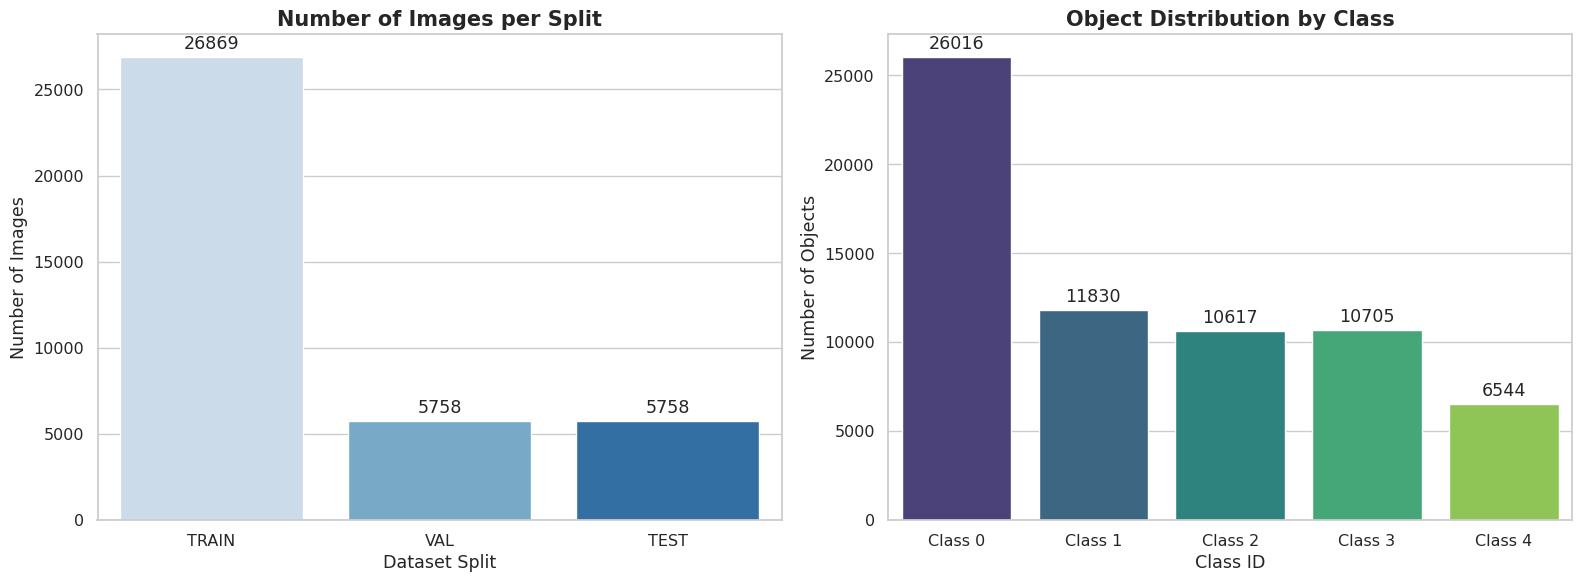

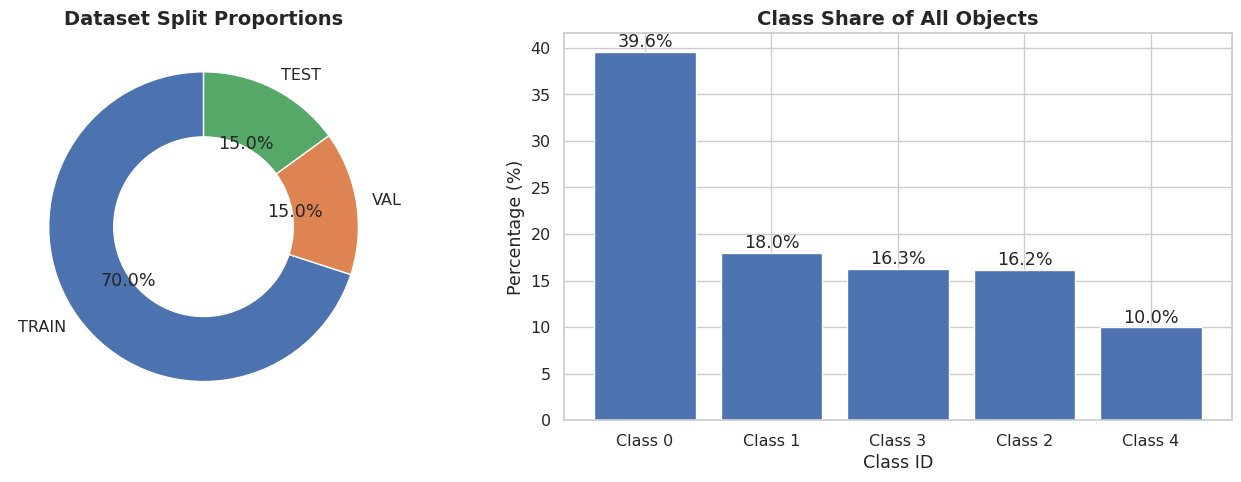

In [10]:

from IPython.display import display

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

split_data = []

for split in ["train", "val", "test"]:
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"

    image_count = sum(
        1 for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    label_files = list(label_dir.glob("*.txt"))
    empty_count = sum(
        1 for p in label_files
        if not p.read_text(encoding="utf-8").strip()
    )

    split_data.append({
        "Dataset Split": split.upper(),
        "Images": image_count,
        "Label Files": len(label_files),
        "Empty Labels": empty_count,
        "Labeled Images (%)": round(
            (len(label_files) - empty_count) / image_count * 100, 2
        ) if image_count else 0
    })

split_df = pd.DataFrame(split_data)

class_df = pd.DataFrame({
    "Class": [f"Class {i}" for i in sorted(class_counts)],
    "Class ID": sorted(class_counts),
    "Objects": [class_counts[i] for i in sorted(class_counts)]
})

class_df["Percentage (%)"] = (
    class_df["Objects"] / class_df["Objects"].sum() * 100
).round(2)

class_df = class_df.sort_values("Objects", ascending=False)

summary_df = pd.DataFrame({
    "Metric": [
        "Total Images",
        "Total Label Files",
        "Total Objects",
        "Empty Label Files",
        "Number of Classes"
    ],
    "Value": [
        split_df["Images"].sum(),
        split_df["Label Files"].sum(),
        class_df["Objects"].sum(),
        split_df["Empty Labels"].sum(),
        len(class_df)
    ]
})

print("ROAD DAMAGE DATASET — SUMMARY")
display(
    summary_df.style
    .hide(axis="index")
    .format({"Value": "{:,}"})
    .background_gradient(subset=["Value"], cmap="Blues")
)

print("DATASET SPLITS")
display(
    split_df.style
    .hide(axis="index")
    .format({
        "Images": "{:,}",
        "Label Files": "{:,}",
        "Empty Labels": "{:,}",
        "Labeled Images (%)": "{:.2f}%"
    })
    .background_gradient(subset=["Images"], cmap="Blues")
)

print("CLASS DISTRIBUTION")
display(
    class_df.style
    .hide(axis="index")
    .format({
        "Objects": "{:,}",
        "Percentage (%)": "{:.2f}%"
    })
    .background_gradient(subset=["Objects"], cmap="YlOrRd")
)

sns.set_theme(style="whitegrid", font_scale=1.05)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=split_df,
    x="Dataset Split",
    y="Images",
    hue="Dataset Split",
    palette="Blues",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Number of Images per Split", fontsize=15, weight="bold")
axes[0].set_xlabel("Dataset Split")
axes[0].set_ylabel("Number of Images")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

sns.barplot(
    data=class_df.sort_values("Class ID"),
    x="Class",
    y="Objects",
    hue="Class",
    palette="viridis",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Object Distribution by Class", fontsize=15, weight="bold")
axes[1].set_xlabel("Class ID")
axes[1].set_ylabel("Number of Objects")
axes[1].tick_params(axis="x", rotation=0)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(
    split_df["Images"],
    labels=split_df["Dataset Split"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)
axes[0].set_title("Dataset Split Proportions", fontsize=14, weight="bold")

axes[1].bar(
    class_df["Class"],
    class_df["Percentage (%)"]
)
axes[1].set_title("Class Share of All Objects", fontsize=14, weight="bold")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xlabel("Class ID")

for i, value in enumerate(class_df["Percentage (%)"]):
    axes[1].text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Image directory exists: True
Label directory exists: True


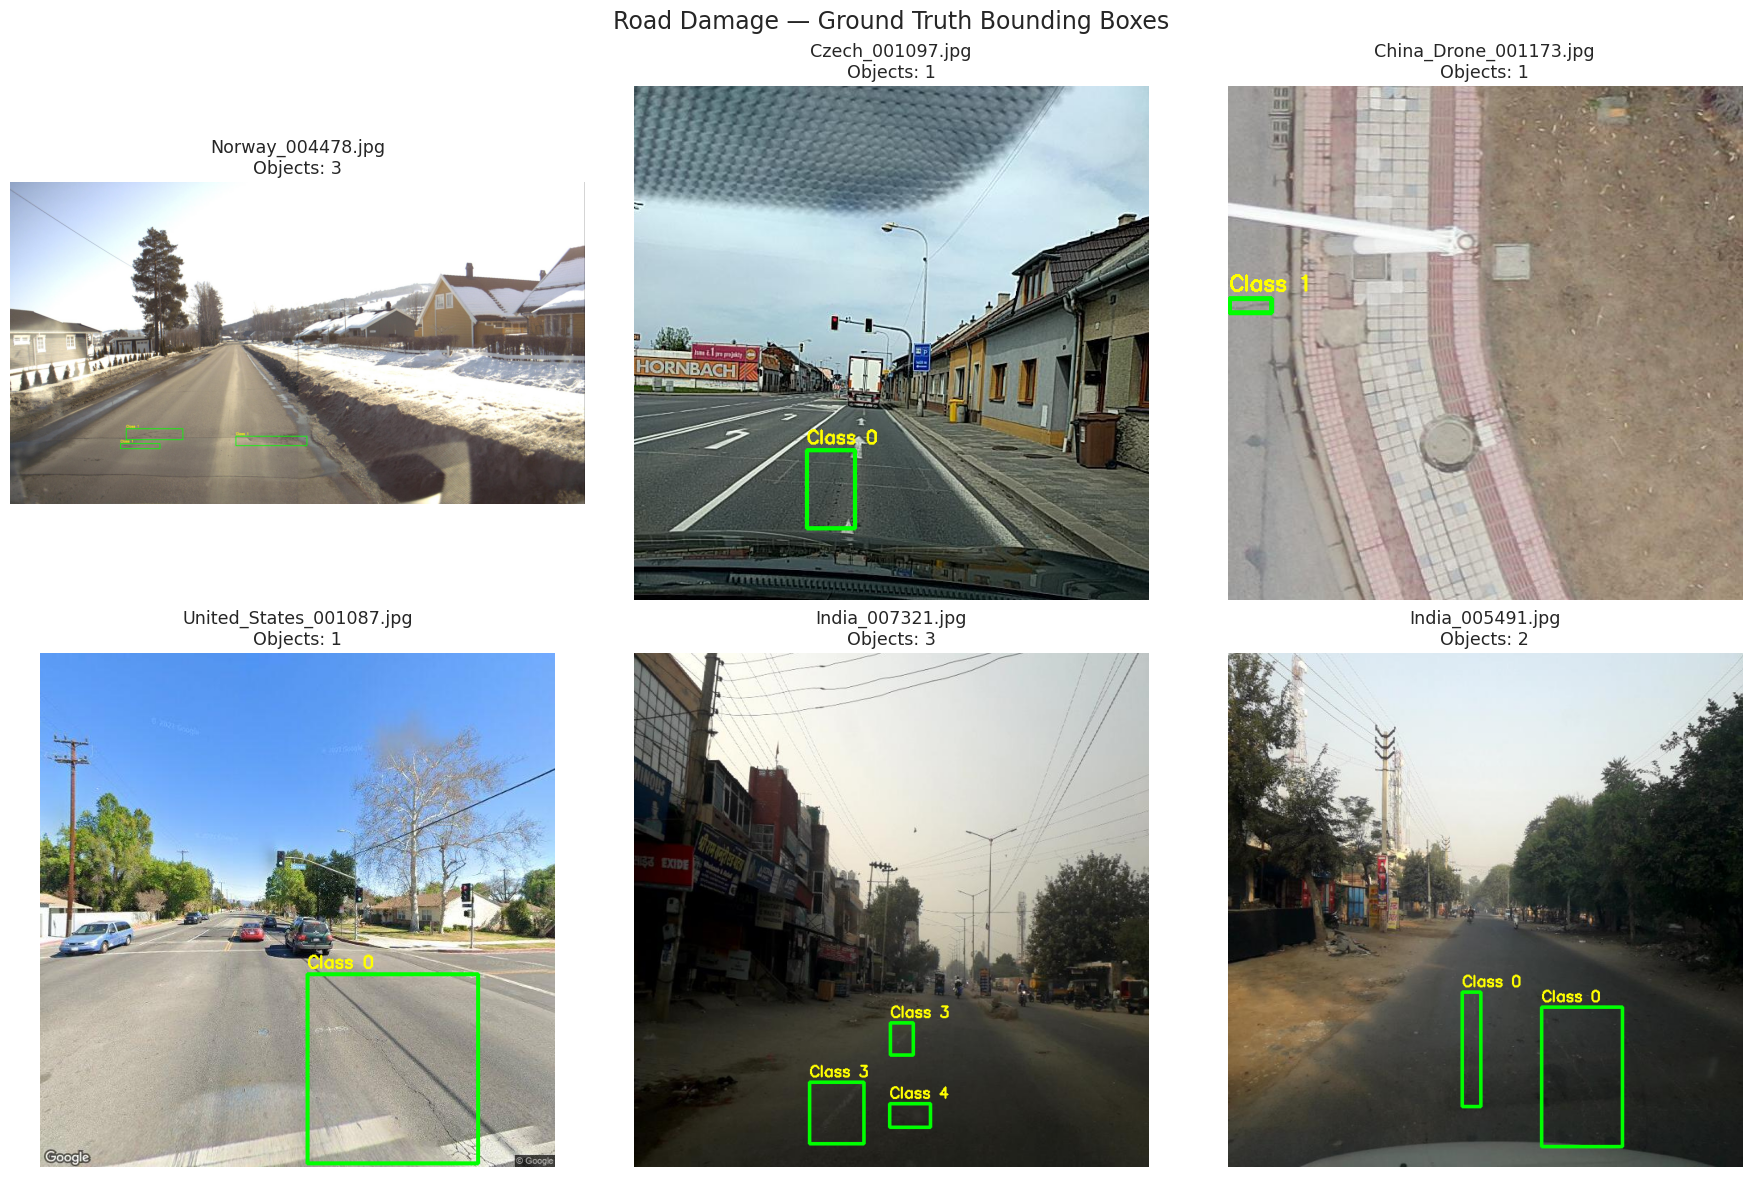

In [13]:
DATA_ROOT = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT")
IMAGE_DIR = DATA_ROOT / "train" / "images"
LABEL_DIR = DATA_ROOT / "train" / "labels"

print("Image directory exists:", IMAGE_DIR.exists())
print("Label directory exists:", LABEL_DIR.exists())

image_files = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

selected_images = random.Random(42).sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, image_path in zip(axes.flatten(), selected_images):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    label_path = LABEL_DIR / f"{image_path.stem}.txt"
    count = 0

    if label_path.exists():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])

            x1 = max(0, int((xc - bw / 2) * width))
            y1 = max(0, int((yc - bh / 2) * height))
            x2 = min(width - 1, int((xc + bw / 2) * width))
            y2 = min(height - 1, int((yc + bh / 2) * height))

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(
                image, f"Class {class_id}",
                (x1, max(y1 - 8, 25)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2
            )
            count += 1

    ax.imshow(image)
    ax.set_title(f"{image_path.name}\nObjects: {count}")
    ax.axis("off")

for ax in axes.flatten()[len(selected_images):]:
    ax.axis("off")

plt.suptitle("Road Damage — Ground Truth Bounding Boxes", fontsize=17)
plt.tight_layout()
plt.show()


In [16]:
yaml_content = f"""
path: {DATA_ROOT}
train: train/images
val: val/images
test: test/images

names:
  0: alligator_crack
  1: transverse_crack
  2: longitudinal_crack
  3: other_corruption
  4: pothole
"""

YAML_PATH.write_text(yaml_content.strip() + "\n", encoding="utf-8")

print(YAML_PATH.read_text())

path: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
train: train/images
val: val/images
test: test/images

names:
  0: alligator_crack
  1: transverse_crack
  2: longitudinal_crack
  3: other_corruption
  4: pothole



In [15]:
model = YOLO("yolov8n.pt")
print("YOLO model loaded successfully")

YOLO model loaded successfully


In [17]:
results = model.train(
    data=str(YAML_PATH),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=4,
    patience=10,
    project="/kaggle/working/road_damage",
    name="yolov8n_road_damage",
    plots=True,
    save=True,
    save_period=5,
    pretrained=True,
    verbose=True
)

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_road_damage, nbs=64, nms=None, opset=None, optimize=Fal

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.61G      2.028      2.575       1.75         21        640: 100% ━━━━━━━━━━━━ 1680/1680 4.7it/s 6:000.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 180/180 3.3it/s 54.3s0.2ss
                   all       5758       9740      0.322      0.261      0.202     0.0824

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.61G      2.106      2.683      1.823         24        640: 100% ━━━━━━━━━━━━ 1680/1680 4.6it/s 6:040.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 180/180 3.3it/s 55.4s0.2ss
                   all       5758       9740        0.3      0.245      0.188     0.0737

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.61G      2.087      2.646      1.837         12        640: 100% ━━━━━━━━━━━━ 1680/1680 4.3it/s 6:310.2ss
                 Cl

In [18]:
best_model = YOLO(
    "/kaggle/working/road_damage/yolov8n_road_damage/weights/best.pt"
)

metrics = best_model.val(
    data=str(YAML_PATH),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 7.7±8.8 MB/s, size: 387.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/labels... 5758 images, 1790 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 47.0it/s 2:020.0ss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 360/360 1.5it/s 4:040.3ss
                   all       5758       9675      0.623      0.543      0.576      0.308
       alligator_crack       2080       3925      0.608      0.516      0.545

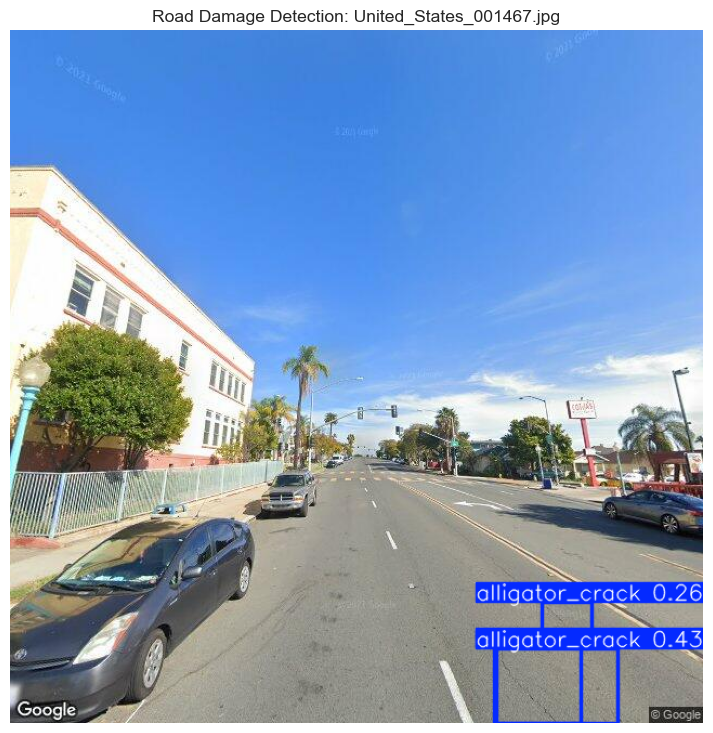

Image: United_States_001467.jpg
Detected objects: 3


In [19]:
TEST_IMAGE_DIR = DATA_ROOT / "test" / "images"

test_images = [
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

test_image = random.Random(42).choice(test_images)

prediction = best_model.predict(
    source=str(test_image),
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False
)

annotated_image = cv2.cvtColor(
    prediction[0].plot(),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 9))
plt.imshow(annotated_image)
plt.title(f"Road Damage Detection: {test_image.name}")
plt.axis("off")
plt.show()

print("Image:", test_image.name)
print("Detected objects:", len(prediction[0].boxes))

In [22]:
class_ids = list(best_model.names.keys())
class_names = list(best_model.names.values())

class_report = pd.DataFrame({
    "Class ID": class_ids,
    "Class Name": class_names,
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.ap
})

display(
    class_report.style.format({
        "mAP50": "{:.2%}",
        "mAP50-95": "{:.2%}"
    })
)

,Class ID,Class Name,mAP50,mAP50-95
0,0,alligator_crack,54.47%,29.52%
1,1,transverse_crack,52.25%,25.42%
2,2,longitudinal_crack,65.06%,34.58%
3,3,other_corruption,72.25%,44.76%
4,4,pothole,44.07%,19.59%


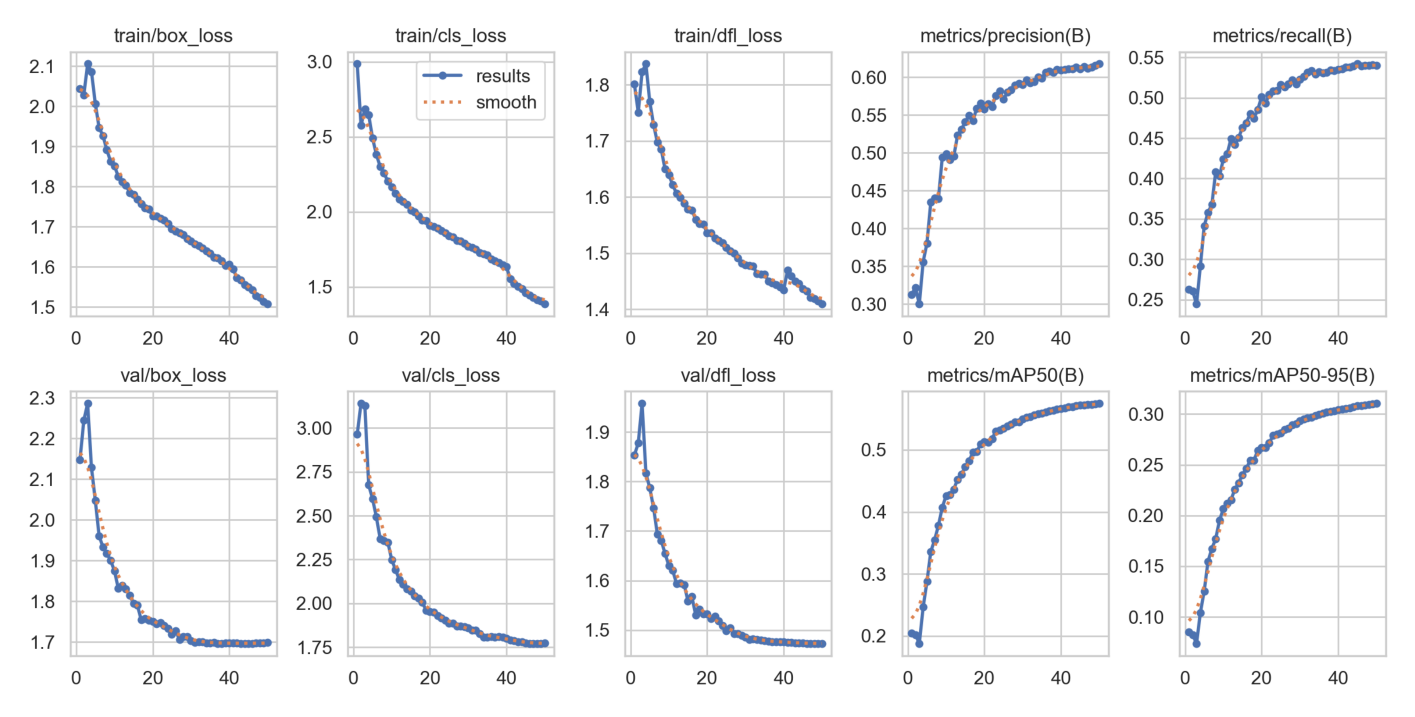

In [21]:
RESULTS_DIR = Path("/kaggle/working/road_damage/yolov8n_road_damage")

if not (RESULTS_DIR / "results.png").exists():
    RESULTS_DIR = Path("/kaggle/working/runs/detect/train")

results_plot = RESULTS_DIR / "results.png"

if results_plot.exists():
    results_image = cv2.imread(str(results_plot))
    results_image = cv2.cvtColor(results_image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(18, 10))
    plt.imshow(results_image)
    plt.axis("off")
    plt.show()
else:
    print("Training results plot not found:", results_plot)

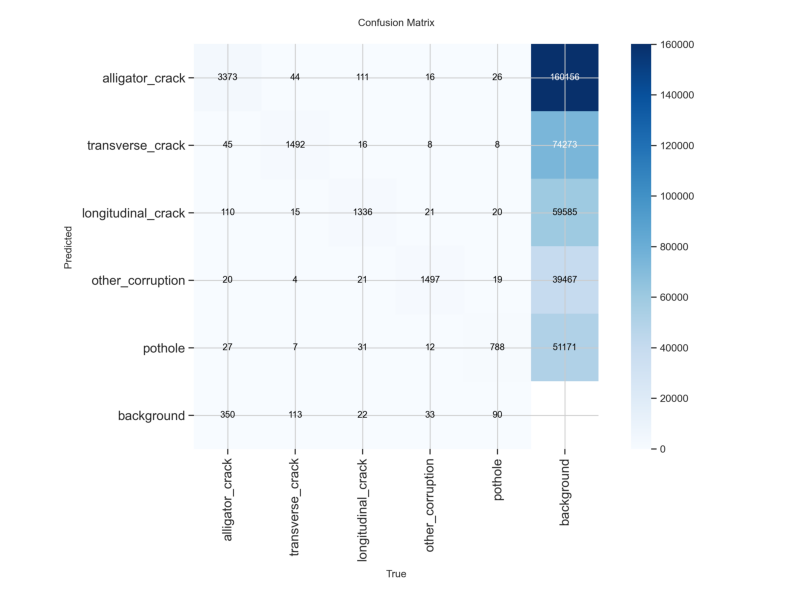

In [26]:
if confusion_matrix_file.exists():
    plt.figure(figsize=(10, 8))
    plt.imshow(plt.imread(confusion_matrix_file))
    plt.axis("off")
    plt.show()
else:
    print("Confusion matrix image not found:", confusion_matrix_file)

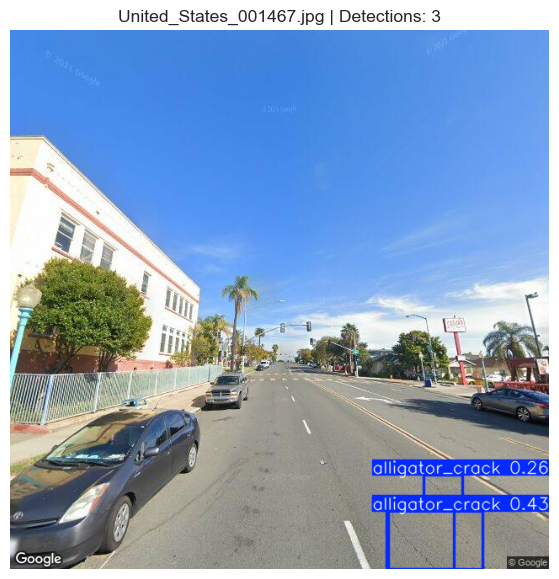

Class: alligator_crack | Confidence: 42.99%
Class: alligator_crack | Confidence: 31.43%
Class: alligator_crack | Confidence: 26.28%


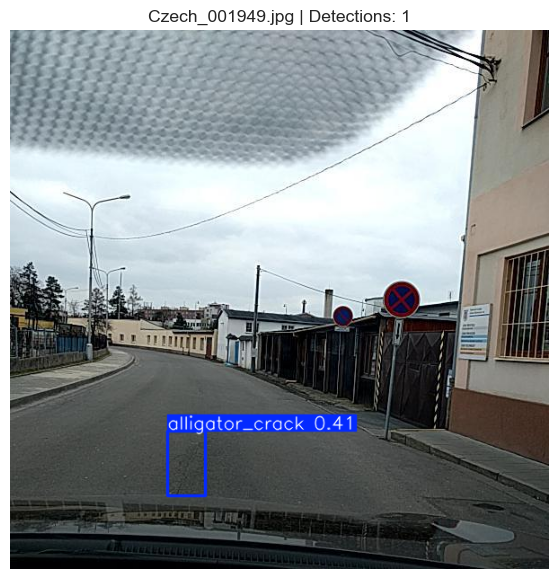

Class: alligator_crack | Confidence: 40.66%


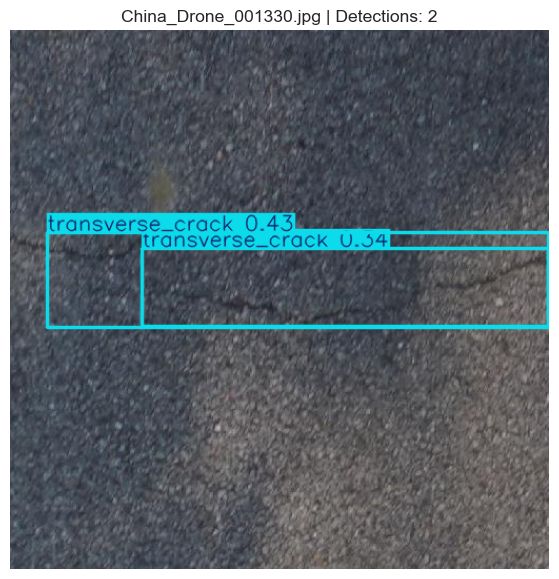

Class: transverse_crack | Confidence: 42.53%
Class: transverse_crack | Confidence: 33.98%


In [28]:
TEST_IMAGE_DIR = DATA_ROOT / "test" / "images"

test_images = [
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

selected_images = random.Random(42).sample(
    test_images,
    min(3, len(test_images))
)

predictions = best_model.predict(
    source=[str(p) for p in selected_images],
    conf=0.25,
    imgsz=640,
    verbose=False
)

for image_path, result in zip(selected_images, predictions):
    annotated_image = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(annotated_image)
    plt.title(f"{image_path.name} | Detections: {len(result.boxes)}")
    plt.axis("off")
    plt.show()

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            f"Class: {best_model.names[class_id]} | "
            f"Confidence: {confidence:.2%}"
        )

In [30]:
import cv2
import gradio as gr
from collections import Counter, defaultdict


OVERALL_COLS = ["Damage Type", "Count", "Share %", "Avg Confidence %", "Images Affected"]
IMAGE_COLS = ["Image", "Damage Type", "Count", "Share in Image %", "Avg Confidence %"]

CSS = """
.gradio-container {
    background: linear-gradient(135deg, #0f172a 0%, #1e1b4b 100%) !important;
    font-family: 'Segoe UI', Tahoma, sans-serif !important;
}
#header {
    text-align: center; padding: 28px 16px; border-radius: 18px;
    background: linear-gradient(90deg, #6366f1, #06b6d4);
    box-shadow: 0 10px 30px rgba(99, 102, 241, 0.35); margin-bottom: 18px;
}
#header h1 { color: #fff; font-size: 2.2rem; margin: 0; }
#header p  { color: #e0f2fe; margin: 8px 0 0; font-size: 1.05rem; }
.panel {
    background: rgba(30, 41, 59, 0.75) !important;
    border: 1px solid rgba(99, 102, 241, 0.35) !important;
    border-radius: 16px !important; padding: 14px !important;
}
#detect-btn {
    background: linear-gradient(90deg, #6366f1, #06b6d4) !important;
    color: #fff !important; font-weight: 700 !important; font-size: 1.05rem !important;
    border: none !important; border-radius: 12px !important;
    transition: transform .15s ease, box-shadow .15s ease;
}
#detect-btn:hover { transform: translateY(-2px); box-shadow: 0 8px 22px rgba(6, 182, 212, 0.45); }
#clear-btn {
    background: #334155 !important; color: #e2e8f0 !important;
    border-radius: 12px !important; border: 1px solid #475569 !important;
}
#summary {
    background: linear-gradient(135deg, rgba(99,102,241,.18), rgba(6,182,212,.18));
    border-radius: 14px; padding: 14px; color: #f1f5f9;
}
label span, .prose, .prose * { color: #e2e8f0 !important; }
footer { display: none !important; }
"""


def empty_tables():
    return pd.DataFrame(columns=OVERALL_COLS), pd.DataFrame(columns=IMAGE_COLS)


def detect_road_damage(files, confidence):
    if not files:
        o, i = empty_tables()
        return [], o, i, "⚠️ ارفع صورة واحدة على الأقل."

    gallery_items, image_rows = [], []
    total_count = Counter()
    total_conf = defaultdict(list)
    images_affected = defaultdict(set)

    for idx, file in enumerate(files, start=1):
        path = file if isinstance(file, str) else file.name
        image_bgr = cv2.imread(path)

        if image_bgr is None:
            image_rows.append([f"Image {idx}", "❌ تعذّر قراءة الصورة", 0, 0.0, 0.0])
            continue

        result = best_model.predict(
            source=image_bgr, conf=confidence, imgsz=640, verbose=False
        )[0]

        annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
        n = len(result.boxes)
        gallery_items.append((annotated, f"Image {idx} — {n} detection(s)"))

        if n == 0:
            image_rows.append([f"Image {idx}", "✅ No damage", 0, 0.0, 0.0])
            continue

        img_count = Counter()
        img_conf = defaultdict(list)
        for box in result.boxes:
            name = best_model.names[int(box.cls[0])]
            score = float(box.conf[0])
            img_count[name] += 1
            img_conf[name].append(score)
            total_count[name] += 1
            total_conf[name].append(score)
            images_affected[name].add(idx)

        for name, cnt in img_count.most_common():
            image_rows.append([
                f"Image {idx}", name, cnt,
                round(cnt / n * 100, 1),
                round(float(np.mean(img_conf[name])) * 100, 1),
            ])

    grand_total = sum(total_count.values())
    overall_rows = []
    for name, cnt in total_count.most_common():
        overall_rows.append([
            name, cnt,
            round(cnt / grand_total * 100, 1),
            round(float(np.mean(total_conf[name])) * 100, 1),
            len(images_affected[name]),
        ])
    if overall_rows:
        all_conf = [s for v in total_conf.values() for s in v]
        overall_rows.append([
            "TOTAL", grand_total, 100.0,
            round(float(np.mean(all_conf)) * 100, 1),
            len(set().union(*images_affected.values())),
        ])

    overall_df = pd.DataFrame(overall_rows, columns=OVERALL_COLS)
    image_df = pd.DataFrame(image_rows, columns=IMAGE_COLS)

    summary = (
        f"## 📊 الملخص\n"
        f"**عدد الصور:** {len(files)}  |  **إجمالي الاكتشافات:** {grand_total}"
    )
    return gallery_items, overall_df, image_df, summary


def clear_all():
    o, i = empty_tables()
    return None, [], o, i, "—", 0.25


theme = gr.themes.Soft(
    primary_hue="indigo", secondary_hue="cyan", neutral_hue="slate",
).set(
    body_background_fill="#0f172a",
    block_background_fill="#1e293b",
    block_border_color="#334155",
    input_background_fill="#0f172a",
)

with gr.Blocks(title="Road Damage Detection", theme=theme, css=CSS) as demo:
    gr.HTML("""
        <div id="header">
            <h1>🛣️ Road Damage Detection</h1>
            <p>ارفع صورة أو أكتر لاكتشاف الشروخ والحفر وباقي أضرار الطريق</p>
        </div>
    """)

    with gr.Row():
        with gr.Column(scale=1, elem_classes="panel"):
            input_files = gr.File(
                label="📤 ارفع صور الطريق (يدعم أكتر من صورة)",
                file_count="multiple", file_types=["image"],
            )
            confidence_slider = gr.Slider(
                minimum=0.1, maximum=0.9, value=0.25, step=0.05,
                label="🎯 Confidence Threshold",
            )
            with gr.Row():
                detect_button = gr.Button("🔍 Detect Road Damage", elem_id="detect-btn", scale=3)
                clear_button = gr.Button("🧹 Clear", elem_id="clear-btn", scale=1)
            summary_box = gr.Markdown("—", elem_id="summary")

        with gr.Column(scale=2, elem_classes="panel"):
            output_gallery = gr.Gallery(
                label="🖼️ نتائج الاكتشاف", columns=2, height=520,
                object_fit="contain", preview=True,
            )

    with gr.Column(elem_classes="panel"):
        gr.Markdown("### 📋 جدول الأضرار ونسبة كل نوع (إجمالي كل الصور)")
        overall_table = gr.Dataframe(
            headers=OVERALL_COLS, interactive=False, wrap=True,
        )

    with gr.Column(elem_classes="panel"):
        gr.Markdown("### 🖼️ جدول تفصيلي لكل صورة")
        image_table = gr.Dataframe(
            headers=IMAGE_COLS, interactive=False, wrap=True,
        )

    detect_button.click(
        fn=detect_road_damage,
        inputs=[input_files, confidence_slider],
        outputs=[output_gallery, overall_table, image_table, summary_box],
    )

    clear_button.click(
        fn=clear_all,
        inputs=None,
        outputs=[input_files, output_gallery, overall_table, image_table, summary_box, confidence_slider],
    )

demo.launch(share=True)

/tmp/ipykernel_49/2475189938.py:139: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Road Damage Detection", theme=theme, css=CSS) as demo:


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://841973d4710783eea1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
